In [1]:
# Cell 1

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution

V_DD, P_out, f0 = 4.85, 1.65, 14.0e6
w0 = 2*np.pi*f0
R_opt = 0.5768 * V_DD**2 / P_out
R_ant = 50.0
w_n2 = 2*np.pi*2*f0    # 28 MHz notch
w_n3 = 2*np.pi*3*f0    # 42 MHz notch

print(f"R_opt = {R_opt:.3f} ohm, f0 = {f0/1e6:.1f} MHz")
print(f"Notches at {2*f0/1e6:.0f} MHz and {3*f0/1e6:.0f} MHz")
print("Topology: 5th-order elliptic, R_opt -> 50, direct transformation")

R_opt = 8.223 ohm, f0 = 14.0 MHz
Notches at 28 MHz and 42 MHz
Topology: 5th-order elliptic, R_opt -> 50, direct transformation


In [2]:
# Cell 2

def abcd_shunt_c(C, w):
    return np.array([[1, 0], [1j*w*C, 1]], dtype=complex)

def abcd_series_parallel_lc(L, C, w):
    denom = 1 - w**2 * L * C
    Z = 1e9 + 0j if abs(denom) < 1e-14 else (1j*w*L) / denom
    return np.array([[1, Z], [0, 1]], dtype=complex)

def s_from_abcd(abcd, R_in, R_out):
    A, B = abcd[0,0], abcd[0,1]
    C, D = abcd[1,0], abcd[1,1]
    d = A + B/R_out + C*R_in + D*R_in/R_out
    return ((A + B/R_out - C*R_in - D*R_in/R_out)/d,
            2.0 * np.sqrt(R_in/R_out)/d)

def ja2gqp5(C1, L2, C2, C3, L4, C4, C5, w):
    """5th-order JA2GQP: shuntC - (L2||C2) - shuntC - (L4||C4) - shuntC."""
    abcd = (abcd_shunt_c(C1, w)
            @ abcd_series_parallel_lc(L2, C2, w)
            @ abcd_shunt_c(C3, w)
            @ abcd_series_parallel_lc(L4, C4, w)
            @ abcd_shunt_c(C5, w))
    return s_from_abcd(abcd, R_opt, R_ant)

In [3]:
# Cell 3

def cost(x):
    C1, L2, C3, L4, C5 = x

    # Series caps derived so that each parallel LC resonates on its target notch
    C2 = 1.0 / (w_n2**2 * L2)
    C4 = 1.0 / (w_n3**2 * L4)

    # Manufacturability: keep every series cap >= 30 pF so parasitics don't
    # move the notch on the board
    if C2 < 30e-12 or C4 < 30e-12:
        return 1e6
    if not (30e-12 < C1 < 1500e-12): return 1e6
    if not (100e-9 < L2 < 1000e-9): return 1e6
    if not (30e-12 < C3 < 1500e-12): return 1e6
    if not (100e-9 < L4 < 500e-9):  return 1e6    # keeps C4 >= 30 pF
    if not (30e-12 < C5 < 1500e-12): return 1e6

    S11_f0, S21_f0 = ja2gqp5(C1, L2, C2, C3, L4, C4, C5, w0)
    S11_2f0, S21_2f0 = ja2gqp5(C1, L2, C2, C3, L4, C4, C5, w_n2)
    S11_3f0, S21_3f0 = ja2gqp5(C1, L2, C2, C3, L4, C4, C5, w_n3)

    # Passband: S21 -> 1, S11 -> 0
    passband = (1 - abs(S21_f0))**2 * 100 + abs(S11_f0)**2 * 100
    # Both notches deep
    notch2 = abs(S21_2f0)**2 * 1000
    notch3 = abs(S21_3f0)**2 * 1000

    return passband + notch2 + notch3

bounds = [
    (30e-12, 1000e-12),    # C1
    (100e-9, 900e-9),      # L2
    (30e-12, 1000e-12),    # C3
    (100e-9, 500e-9),      # L4
    (30e-12, 1000e-12),    # C5
]

result = differential_evolution(
    cost, bounds,
    strategy='best1bin', popsize=40, maxiter=4000,
    tol=1e-14, seed=42, polish=True, disp=False,
)

C1, L2, C3, L4, C5 = result.x
C2 = 1.0 / (w_n2**2 * L2)
C4 = 1.0 / (w_n3**2 * L4)

print(f"\n=== 5th-order JA2GQP-style elliptic ===")
print(f"  C1 (shunt)             = {C1*1e12:.1f} pF")
print(f"  L2 (series, notch 2f0) = {L2*1e9:.1f} nH")
print(f"  C2 (series, notch 2f0) = {C2*1e12:.1f} pF")
print(f"  C3 (shunt)             = {C3*1e12:.1f} pF")
print(f"  L4 (series, notch 3f0) = {L4*1e9:.1f} nH")
print(f"  C4 (series, notch 3f0) = {C4*1e12:.1f} pF")
print(f"  C5 (shunt)             = {C5*1e12:.1f} pF")
print(f"\n  L2·C2 resonance = {1/(2*np.pi*np.sqrt(L2*C2))/1e6:.2f} MHz (target {2*f0/1e6:.0f})")
print(f"  L4·C4 resonance = {1/(2*np.pi*np.sqrt(L4*C4))/1e6:.2f} MHz (target {3*f0/1e6:.0f})")


=== 5th-order JA2GQP-style elliptic ===
  C1 (shunt)             = 551.2 pF
  L2 (series, notch 2f0) = 145.3 nH
  C2 (series, notch 2f0) = 222.4 pF
  C3 (shunt)             = 836.9 pF
  L4 (series, notch 3f0) = 412.9 nH
  C4 (series, notch 3f0) = 34.8 pF
  C5 (shunt)             = 220.2 pF

  L2·C2 resonance = 28.00 MHz (target 28)
  L4·C4 resonance = 42.00 MHz (target 42)



  S11(f0)  =   -67.7 dB
  S21(f0)  =  -0.000 dB
  S21(2f0) =   -95.9 dBc
  S21(3f0) =  -109.3 dBc
  S21(4f0) =   -48.6 dBc
  S21(5f0) =   -46.4 dBc


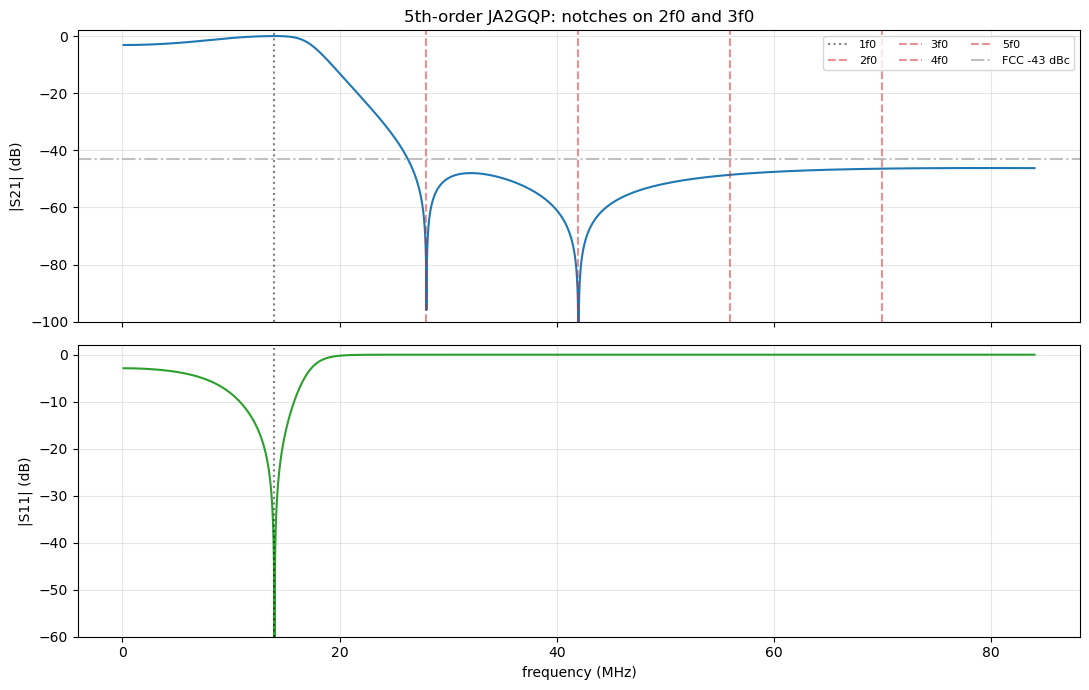

In [4]:
# Cell 4

w_rad = np.linspace(2*np.pi*0.1e6, 2*np.pi*6*f0, 5000)
f_hz = w_rad / (2*np.pi)
S11, S21 = zip(*[ja2gqp5(C1, L2, C2, C3, L4, C4, C5, w) for w in w_rad])
S11_dB = 20*np.log10(np.maximum(np.abs(S11), 1e-30))
S21_dB = 20*np.log10(np.maximum(np.abs(S21), 1e-30))

i_f0  = np.argmin(np.abs(f_hz - f0))
i_2f0 = np.argmin(np.abs(f_hz - 2*f0))
i_3f0 = np.argmin(np.abs(f_hz - 3*f0))
i_4f0 = np.argmin(np.abs(f_hz - 4*f0))
i_5f0 = np.argmin(np.abs(f_hz - 5*f0))

print(f"\n  S11(f0)  = {S11_dB[i_f0]:7.1f} dB")
print(f"  S21(f0)  = {S21_dB[i_f0]:7.3f} dB")
print(f"  S21(2f0) = {S21_dB[i_2f0]-S21_dB[i_f0]:7.1f} dBc")
print(f"  S21(3f0) = {S21_dB[i_3f0]-S21_dB[i_f0]:7.1f} dBc")
print(f"  S21(4f0) = {S21_dB[i_4f0]-S21_dB[i_f0]:7.1f} dBc")
print(f"  S21(5f0) = {S21_dB[i_5f0]-S21_dB[i_f0]:7.1f} dBc")

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(f_hz/1e6, S21_dB, 'C0', lw=1.5)
for n in range(1, 6):
    ax[0].axvline(n*f0/1e6, color='C3' if n > 1 else 'k', ls='--' if n > 1 else ':',
                  alpha=0.5, label=f'{n}f0' if n < 6 else None)
ax[0].axhline(-43, color='gray', ls='-.', alpha=0.5, label='FCC -43 dBc')
ax[0].set_ylabel('|S21| (dB)'); ax[0].set_ylim(-100, 2)
ax[0].set_title('5th-order JA2GQP: notches on 2f0 and 3f0')
ax[0].legend(fontsize=8, ncol=3); ax[0].grid(alpha=0.3)

ax[1].plot(f_hz/1e6, S11_dB, 'C2', lw=1.5)
ax[1].axvline(f0/1e6, color='k', ls=':', alpha=0.5)
ax[1].set_xlabel('frequency (MHz)'); ax[1].set_ylabel('|S11| (dB)')
ax[1].set_ylim(-60, 2); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()